## Import Resources

In this project, you will train an image classifier to recognize different species of flowers. You can imagine using something like this in a phone app that tells you the name of the flower your camera is looking at. In practice, you will train this classifier, then export it for use in your application. We will be using this dataset(https://www.kaggle.com/datasets/waseemalastal/the-oxford-flowers-102-dataset) from Oxford of 102 flower categories. 

The project is broken down into multiple steps:
- Load the image dataset and create a pipeline
- Build and Train an image classifer on this dataset
- Use your trained model to perform inference on flower images


In [31]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image_dataset_from_directory

## Load the Dataset

Here I use tensorflow_dataset to load Oxford Flower 102 dataset. This dataset has 3 splits: 'train', 'test', and 'validation'. You will also need to make sure the training data is normalized and resized to 224x224 pixels as required by the pre-trained networks.

The validation and testing sets are used to measure model's performance on data it has not seen yet, but you will need to normalize and resize the images to appropriate size. 


In [32]:
import tensorflow as tf

data_dir = "./flower_data"

# Load datasets from local folders
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{data_dir}/train",
    label_mode="int"
)

class_names = train_ds.class_names


val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{data_dir}/valid",
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{data_dir}/test",
    labels=None,
    shuffle=False
)

num_train = len(train_ds.file_paths)
num_valid = len(val_ds.file_paths)
num_test = len(test_ds.file_paths)
num_classes = len(class_names)


Found 6552 files belonging to 102 classes.
Found 818 files belonging to 102 classes.
Found 819 files.


## Explore the Dataset

In [33]:

print(f"Training examples: {num_train}")
print(f"Validation examples: {num_valid}")
print(f"Test examples: {num_test}")
print(f"Classes: {num_classes}")

Training examples: 6552
Validation examples: 818
Test examples: 819
Classes: 102


In [34]:
import json

with open('./flower_data/cat_to_name.json') as f:
    label_map = json.load(f)

for image, label in train_ds.take(3):
    print(f"Image shape: {image.shape}, Labels: {label_map[str(label[0].numpy())]}")

Image shape: (32, 256, 256, 3), Labels: poinsettia
Image shape: (32, 256, 256, 3), Labels: oxeye daisy
Image shape: (32, 256, 256, 3), Labels: fritillary


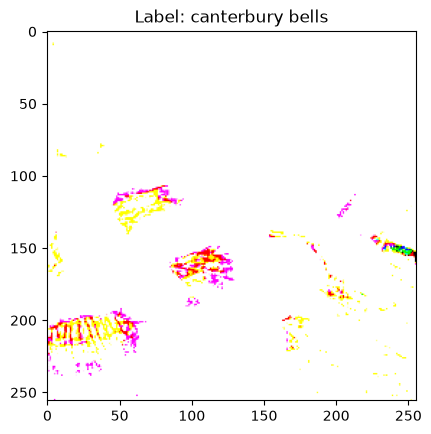

In [35]:
import matplotlib.pyplot as plt
import json

with open('./flower_data/cat_to_name.json') as f:
    label_map = json.load(f)

for image, label in train_ds.take(1):
    plt.imshow(image[0].numpy())
    plt.title(f"Label: {label_map[str(label[0].numpy())]}")
    plt.show()

## Creat Pipeline

In [36]:
import tensorflow as tf

def preprocess(image, label):
    image = tf.image.resize(image, (224, 224))  
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def preprocess_test(image):
    image = tf.image.resize(image, (224, 224))  
    return tf.cast(image, tf.float32) / 255.0

# Apply preprocessing
train_ds = train_ds.map(preprocess)
val_ds = val_ds.map(preprocess)
test_ds = test_ds.map(preprocess_test)

# Prefetching to improve performance by preparing the next batch while the current batch is being processed
train_ds = train_ds.prefetch(tf.data.experimental.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.experimental.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.experimental.AUTOTUNE)

## Build and Train the Classifier

I use MobileNet pre-trained model from Tensorflow Hub to get the image features. Build and train new feed-forward classifier using those features.

- Load the MobileNet pre-trained network from TensorFlow Hub
- Define a new, untrained feed-forward network as classifier
- Train the classifier
- Plot the loss and accuracy values achieved during training and validation set
- Save model as Keras model



In [40]:
# TODO: Build and train your network.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_hub as hub
import matplotlib.pyplot as plt
import tensorflow as tf

base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(102, activation='softmax')
])


model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_ds,
                    epochs=30,
                    validation_data=val_ds,
                    verbose=1,
                    callbacks=[early_stopping])




Epoch 1/30


d:\python-envs\pytorch-gpu\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


205/205 ━━━━━━━━━━━━━━━━━━━━ 161s 766ms/step - accuracy: 0.4754 - loss: 2.2878 - val_accuracy: 0.8105 - val_loss: 0.8726
Epoch 2/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 149s 727ms/step - accuracy: 0.7926 - loss: 0.7843 - val_accuracy: 0.8496 - val_loss: 0.5897
Epoch 3/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 129s 630ms/step - accuracy: 0.8654 - loss: 0.4922 - val_accuracy: 0.8582 - val_loss: 0.5151
Epoch 4/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 140s 681ms/step - accuracy: 0.9029 - loss: 0.3471 - val_accuracy: 0.8716 - val_loss: 0.4497
Epoch 5/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 144s 704ms/step - accuracy: 0.9254 - loss: 0.2624 - val_accuracy: 0.8741 - val_loss: 0.4206
Epoch 6/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 143s 698ms/step - accuracy: 0.9492 - loss: 0.1953 - val_accuracy: 0.8790 - val_loss: 0.4307
Epoch 7/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 134s 650ms/step - accuracy: 0.9536 - loss: 0.1584 - val_accuracy: 0.8863 - val_loss: 0.3916
Epoch 8/30
205/205 ━━━━━━━━━━━━━━━━━━━━ 130s 633ms/step - accuracy: 0.9664 - loss: 0.12

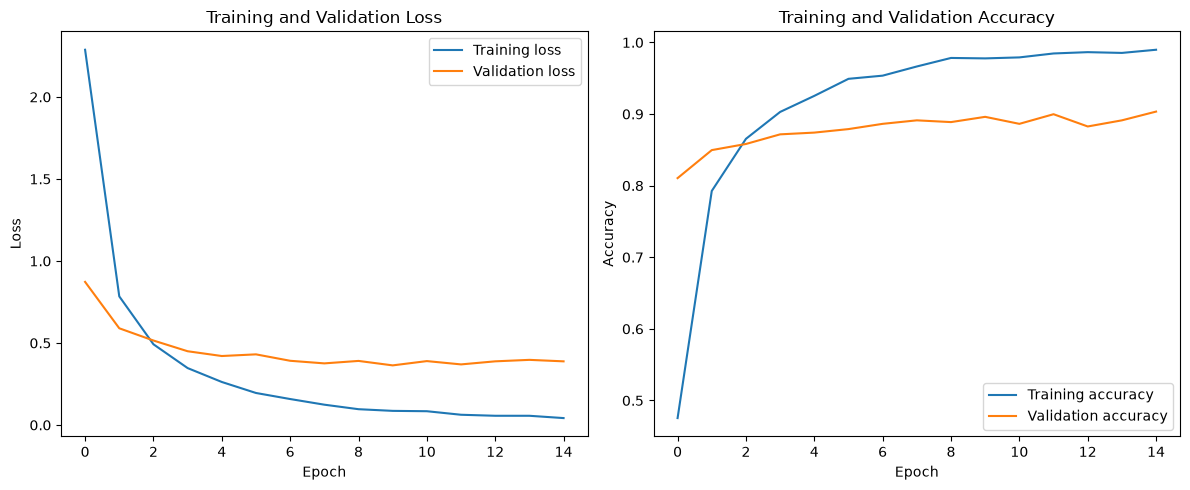

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## Testing Network

In [79]:
import numpy as np

predictions = model.predict(test_ds)

predicted_indices = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1)

print("Number of predictions:", len(predicted_indices))

26/26 ━━━━━━━━━━━━━━━━━━━━ 17s 558ms/step
Number of predictions: 819


## Save the Model


In [77]:
model.save('flower_classifier_model.keras')

## Load the Keras Model

In [78]:
loaded_model = tf.keras.models.load_model(
    "flower_classifier_model.keras"
)

loaded_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 102)            │       104,550 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,506,868 (24.82 MB)

 Trainable params: 1,416,294 (5.40 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2,832,590 (10.81 MB)

## Inference for classification


### Image Pre-processing

In [45]:
import tensorflow as tf
from PIL import Image
import numpy as np

def process_image(image_path):
    image = Image.open(image_path)
    
    image = np.asarray(image)
    
    image = tf.convert_to_tensor(image, dtype=tf.float32)
    
    image = tf.image.resize(image, (224, 224))
    
    image = image / 255.0
    
    return image.numpy()

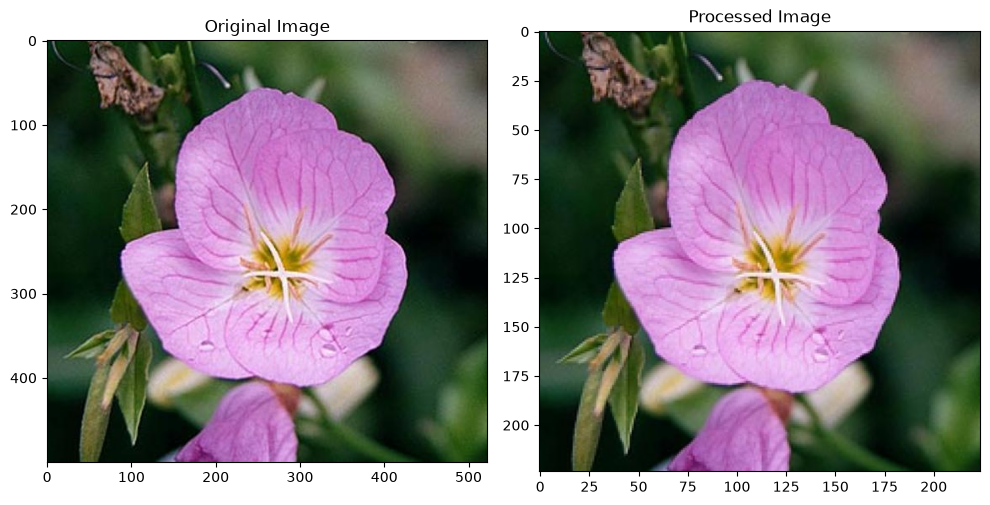

In [69]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image_path = './test_images/pink-primrose.jpg'

im = Image.open(image_path)
test_image = np.asarray(im)

processed_test_image = process_image(image_path)

fix, (ax1, ax2) = plt.subplots(figsize=(10, 10), ncols=2)

ax1.imshow(test_image)
ax1.set_title('Original Image')

ax2.imshow(processed_test_image)
ax2.set_title('Processed Image')

plt.tight_layout()
plt.show()

## Inference


In [70]:
def predict(image_path, model, top_k=5):
    
    image = process_image(image_path)
    
    image = np.expand_dims(image, axis=0)
    
    predictions = model.predict(image)
    
    top_k_probs = tf.nn.top_k(predictions[0], k=top_k)
    
    return top_k_probs.values.numpy(), top_k_probs.indices.numpy().astype(str)

## Sanity Check

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


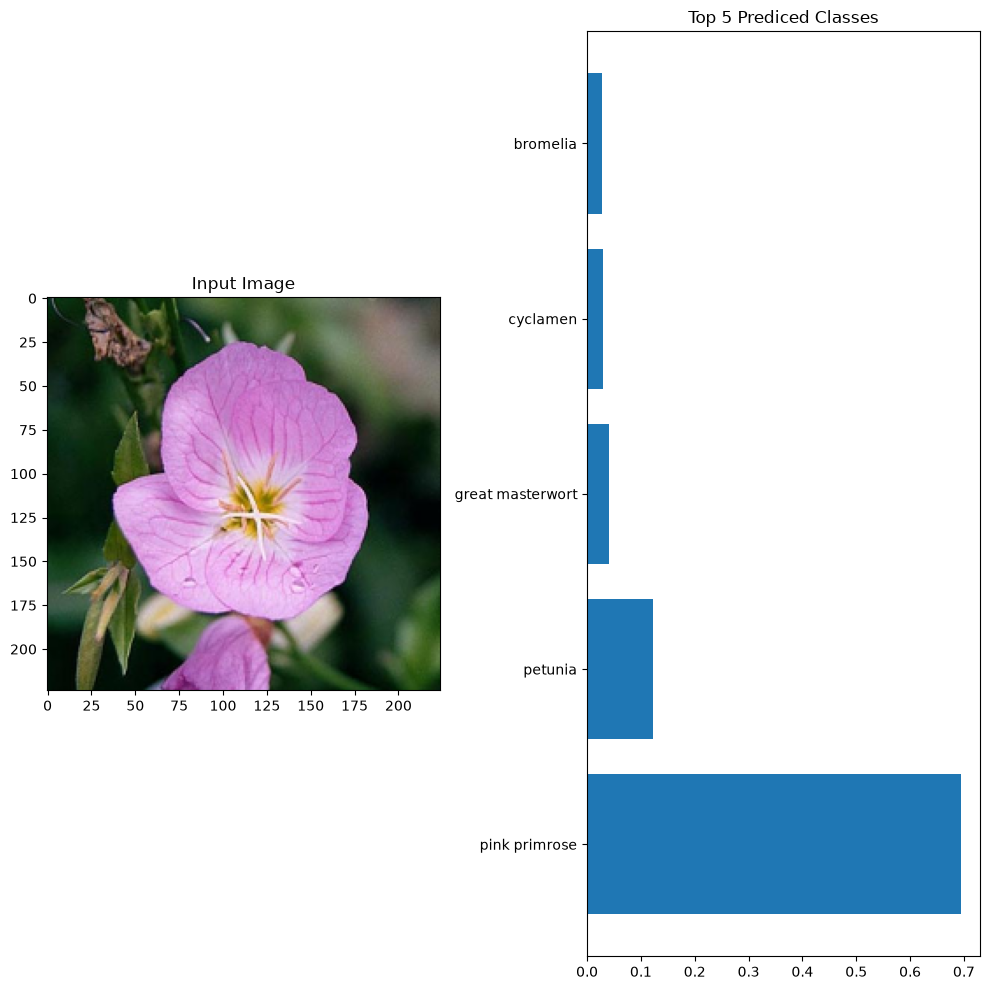

In [76]:
class_names = {
    "21": "fire lily",
    "3": "canterbury bells",
    "45": "bolero deep blue",
    "1": "pink primrose",
    "34": "mexican aster",
    "27": "prince of wales feathers",
    "7": "moon orchid",
    "16": "globe-flower",
    "25": "grape hyacinth",
    "26": "corn poppy",
    "79": "toad lily",
    "39": "siam tulip",
    "24": "red ginger",
    "67": "spring crocus",
    "35": "alpine sea holly",
    "32": "garden phlox",
    "10": "globe thistle",
    "6": "tiger lily",
    "93": "ball moss",
    "33": "love in the mist",
    "9": "monkshood",
    "102": "blackberry lily",
    "14": "spear thistle",
    "19": "balloon flower",
    "100": "blanket flower",
    "13": "king protea",
    "49": "oxeye daisy",
    "15": "yellow iris",
    "61": "cautleya spicata",
    "31": "carnation",
    "64": "silverbush",
    "68": "bearded iris",
    "63": "black-eyed susan",
    "69": "windflower",
    "62": "japanese anemone",
    "20": "giant white arum lily",
    "38": "great masterwort",
    "4": "sweet pea",
    "86": "tree mallow",
    "101": "trumpet creeper",
    "42": "daffodil",
    "22": "pincushion flower",
    "2": "hard-leaved pocket orchid",
    "54": "sunflower",
    "66": "osteospermum",
    "70": "tree poppy",
    "85": "desert-rose",
    "99": "bromelia",
    "87": "magnolia",
    "5": "english marigold",
    "92": "bee balm",
    "28": "stemless gentian",
    "97": "mallow",
    "57": "gaura",
    "40": "lenten rose",
    "47": "marigold",
    "59": "orange dahlia",
    "48": "buttercup",
    "55": "pelargonium",
    "36": "ruby-lipped cattleya",
    "91": "hippeastrum",
    "29": "artichoke",
    "71": "gazania",
    "90": "canna lily",
    "18": "peruvian lily",
    "98": "mexican petunia",
    "8": "bird of paradise",
    "30": "sweet william",
    "17": "purple coneflower",
    "52": "wild pansy",
    "84": "columbine",
    "12": "colt's foot",
    "11": "snapdragon",
    "96": "camellia",
    "23": "fritillary",
    "50": "common dandelion",
    "44": "poinsettia",
    "53": "primula",
    "72": "azalea",
    "65": "californian poppy",
    "80": "anthurium",
    "76": "morning glory",
    "37": "cape flower",
    "56": "bishop of llandaff",
    "60": "pink-yellow dahlia",
    "82": "clematis",
    "58": "geranium",
    "75": "thorn apple",
    "41": "barbeton daisy",
    "95": "bougainvillea",
    "43": "sword lily",
    "83": "hibiscus",
    "78": "lotus",
    "88": "cyclamen",
    "94": "foxglove",
    "81": "frangipani",
    "74": "rose",
    "89": "watercress",
    "73": "water lily",
    "46": "wallflower",
    "77": "passion flower",
    "51": "petunia"
}

def sanity_check(image_path, model, top_k):
    probs, classes = predict(image_path, model, top_k)
    
    test_image = process_image(image_path)
    
    class_labels = [class_names.get(str(int(i)+1), 'Unknown') for i in classes]
    
    fix, (ax1, ax2) = plt.subplots(figsize=(10, 10), ncols=2)
    
    ax1.imshow(test_image)
    ax1.set_title('Input Image')
    
    ax2.barh(class_labels, probs)
    ax2.set_title('Top 5 Prediced Classes')
    ax2.set_label('Probability')
    
    plt.tight_layout()
    plt.show()
    
image_path = './test_images/pink-primrose.jpg'  
sanity_check(image_path, model, top_k=5)